# Chapter 5 metrics
Computes the metrics that are not printed in `targeted_results.ipynb`, `targeted_analysis.ipynb` and `model_analysis.ipynb` yet. 

In [18]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/content/drive/MyDrive/master-thesis").resolve()
NOTEBOOK_DIR = PROJECT_ROOT / "notebooks"
RESULTS = PROJECT_ROOT / "notebooks/results_targeted"
RUNS = {"held-out": RESULTS / "with_validation_time", "same-window": RESULTS / "no_validation_time"}
RUN_DIR = NOTEBOOK_DIR / "results_targeted/with_validation_time"
SUFFIX = "_3"
STRATEGIES = ["MA", "ROC", "BB"]
REGIME = {"LSTM": "LSTM-13y", "LSTM3y": "LSTM-3y", "LSTM_cumulative": "LSTM-cumulative", "LSTM_rolling": "LSTM-rolling"}
pd.set_option("display.precision", 3)

def load_run(run):
    frames = []
    for s in STRATEGIES:
        df = pd.read_csv(RUNS[run] / f"ALL_LSTM_{s}{SUFFIX}" / f"ALL_LSTM_{s}.csv")
        df["strategy"] = s
        frames.append(df)
    t = pd.concat(frames, ignore_index=True)
    b = lambda c: t[c].astype(str).str.lower().isin({"true", "1", "yes"})
    t["valid"], t["success"], t["trivial"] = b("valid"), b("success"), b("already_target")
    t = t[t["valid"]].copy()
    t["nt"] = ~t["trivial"]
    t["succ"] = t["success"] & t["nt"]
    t["harm"] = t["succ"] & (t["delta_cumulative_return_in_period"] < 0)
    t["k"] = t["min_abs_delta_norm"].where(t["succ"])
    t["final"] = t["delta_final_cr"].where(t["succ"])
    t["cr20"] = t["delta_cumulative_return_in_period"].where(t["succ"])
    t["regime"] = t["model"].map(REGIME)
    t["kind"] = np.where(t["regime"].isin(["LSTM-13y", "LSTM-3y"]), "fixed", "periodic")
    return t

def agg(df, by):
    """ASR_nt, CR_SR and P_harm with their counts."""
    g = df.groupby(by).agg(non_trivial=("nt", "sum"), successes=("succ", "sum"), harmful=("harm", "sum"),
                           mean_k=("k", "mean"), mean_cr20=("cr20", "mean"), mean_final=("final", "mean"))
    g["ASR_nt"] = g["successes"] / g["non_trivial"]
    g["CR_SR"] = g["harmful"] / g["successes"]
    g["P_harm"] = g["harmful"] / g["non_trivial"]
    return g

def show(label, value):
    v = f"{value:,}" if isinstance(value, (int, np.integer)) else f"{value:.3f}"
    print(f"{label:<60s} {v:>8s}")

ho, sw = load_run("held-out"), load_run("same-window")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1 - Run and ATS characterization (5.1)

In [19]:
for name, t in (("Held-out", ho), ("Same-window", sw)):
    per_setup = t.groupby("setup").size()
    show(f"{name}: valid trials", int(len(t)))
    show(f"{name}: min valid trials per setup", int(per_setup.min()))
    show(f"{name}: max valid trials per setup", int(per_setup.max()))

# Ratios of the RMSE of Table tab:ats-characterisation (values printed by model_analysis.ipynb)
rmse = pd.DataFrame({"mean": [4.92, 6.55, 10.52, 4.45], "median": [3.66, 5.78, 8.84, 3.68]},
                    index=["LSTM-13y", "LSTM-3y", "LSTM-cumulative", "LSTM-rolling"])
print("\nRMSE relative to the most accurate regime (lowest mean / lowest median):")
display(rmse / rmse.min())

Held-out: valid trials                                          1,728
Held-out: min valid trials per setup                              144
Held-out: max valid trials per setup                              144
Same-window: valid trials                                       1,620
Same-window: min valid trials per setup                           130
Same-window: max valid trials per setup                           138

RMSE relative to the most accurate regime (lowest mean / lowest median):


,mean,median
LSTM-13y,1.106,1.000
LSTM-3y,1.472,1.579
LSTM-cumulative,2.364,2.415
LSTM-rolling,1.000,1.005


## 2 - Strategy, timing and training overview (`tab:held-out-overview`)

In [20]:
display(agg(ho, ["strategy", "regime"])[["non_trivial", "successes", "ASR_nt", "harmful", "P_harm"]])
display(agg(ho, "strategy").loc[STRATEGIES, ["non_trivial", "successes", "ASR_nt", "mean_k", "harmful", "CR_SR", "P_harm"]])

non_trivial  successes  ASR_nt  harmful  P_harm
strategy regime                                                          
BB       LSTM-13y                 131         29   0.221        5   0.038
         LSTM-3y                  136         36   0.265        1   0.007
         LSTM-cumulative           72          0   0.000        0   0.000
         LSTM-rolling             106          5   0.047        2   0.019
MA       LSTM-13y                  72         18   0.250        9   0.125
         LSTM-3y                   74         17   0.230        9   0.122
         LSTM-cumulative           73         11   0.151        5   0.068
         LSTM-rolling              72          4   0.056        2   0.028
ROC      LSTM-13y                  88         45   0.511       15   0.170
         LSTM-3y                   78         28   0.359        7   0.090
         LSTM-cumulative           90         10   0.111        3   0.033
         LSTM-rolling              93          8   0.086        1   0.011

,non_trivial,successes,ASR_nt,mean_k,harmful,CR_SR,P_harm
strategy,,,,,,,
MA,291,50,0.172,0.744,25,0.500,0.086
ROC,349,91,0.261,0.915,26,0.286,0.074
BB,445,70,0.157,0.961,8,0.114,0.018


## 3 - Effect of the strategy (5.2.1)

In [21]:
fixed = ho[ho["kind"] == "fixed"]

# Moving Average on the fixed regimes: near_strategy_boundary against the other policies
ma = fixed[fixed["strategy"] == "MA"]
nb = ma["timing_policy"] == "near_strategy_boundary"
show("MA, fixed, near_strategy_boundary: non-trivial trials", int(ma[nb]["nt"].sum()))
show("MA, fixed, near_strategy_boundary: successes", int(ma[nb]["succ"].sum()))
show("MA, fixed, near_strategy_boundary: mean |k| of the successes", ma[nb]["k"].mean())
show("MA, fixed, other policies: non-trivial trials", int(ma[~nb]["nt"].sum()))
show("MA, fixed, other policies: successes", int(ma[~nb]["succ"].sum()))

# Rate of Change on the fixed regimes: uniform baseline and objectives
roc = fixed[fixed["strategy"] == "ROC"]
u = roc[roc["timing_policy"] == "uniform"]
show("ROC, fixed, uniform: non-trivial trials", int(u["nt"].sum()))
show("ROC, fixed, uniform: successes", int(u["succ"].sum()))
print("\nROC, fixed regimes, per objective:")
display(agg(roc, ["regime", "objective"])[["non_trivial", "successes", "ASR_nt"]])

# Bollinger Bands: objectives and baseline signal on the attacked days
bb = ho[ho["strategy"] == "BB"]
print("BB, per objective:")
display(agg(bb, "objective")[["non_trivial", "successes", "ASR_nt"]])
show("BB: share of trials with baseline signal buy", (bb["baseline_signal"] == 1).mean())
show("BB: share of trials with baseline signal sell", (bb["baseline_signal"] == -1).mean())
show("BB, LSTM-cumulative: share with baseline signal buy",
     (bb[bb["regime"] == "LSTM-cumulative"]["baseline_signal"] == 1).mean())

MA, fixed, near_strategy_boundary: non-trivial trials              26
MA, fixed, near_strategy_boundary: successes                       26
MA, fixed, near_strategy_boundary: mean |k| of the successes    0.267
MA, fixed, other policies: non-trivial trials                     120
MA, fixed, other policies: successes                                9
ROC, fixed, uniform: non-trivial trials                            28
ROC, fixed, uniform: successes                                     17

ROC, fixed regimes, per objective:


non_trivial  successes  ASR_nt
regime   objective                                 
LSTM-13y force_buy            27         18   0.667
         force_sell           61         27   0.443
LSTM-3y  force_buy            22         15   0.682
         force_sell           56         13   0.232

BB, per objective:


,non_trivial,successes,ASR_nt
objective,,,
force_buy,166,67,0.404
force_sell,279,3,0.011


BB: share of trials with baseline signal buy                    0.424
BB: share of trials with baseline signal sell                   0.031
BB, LSTM-cumulative: share with baseline signal buy             1.000


## 4 - Effect of the timing policy (5.2.2)

In [22]:
pol = agg(ho, ["strategy", "timing_policy"])["ASR_nt"].unstack(0)[STRATEGIES]
print("near_strategy_boundary and weak_trend relative to the uniform baseline (ASR_nt ratio):")
display(pol.loc[["near_strategy_boundary", "weak_trend"]] / pol.loc["uniform"])

b = fixed[fixed["timing_policy"] == "near_strategy_boundary"]
display(agg(b, "strategy").loc[STRATEGIES, ["non_trivial", "successes"]].rename_axis("near_strategy_boundary, fixed regimes"))

near_strategy_boundary and weak_trend relative to the uniform baseline (ASR_nt ratio):


strategy,MA,ROC,BB
timing_policy,,,
near_strategy_boundary,8.941,2.147,2.61
weak_trend,2.000,0.902,1.50


,non_trivial,successes
"near_strategy_boundary, fixed regimes",,
MA,26,26
ROC,36,31
BB,39,15


## 5 - Effect of the training regime (5.2.3)

In [23]:
display(agg(ho, "regime")[["non_trivial", "successes", "ASR_nt"]])
display(agg(ho, "kind")[["non_trivial", "successes", "ASR_nt"]])

,non_trivial,successes,ASR_nt
regime,,,
LSTM-13y,291,92,0.316
LSTM-3y,288,81,0.281
LSTM-cumulative,235,21,0.089
LSTM-rolling,271,17,0.063


,non_trivial,successes,ASR_nt
kind,,,
fixed,579,173,0.299
periodic,506,38,0.075


## 6 - Temporal robustness (5.3.1)

In [24]:
comp = pd.DataFrame({"same-window": agg(sw, "strategy")["ASR_nt"], "held-out": agg(ho, "strategy")["ASR_nt"]}).loc[STRATEGIES]
print("ASR_nt per strategy:"); display(comp)
print("ASR_nt fixed vs periodic:")
display(pd.DataFrame({"same-window": agg(sw, "kind")["ASR_nt"], "held-out": agg(ho, "kind")["ASR_nt"]}))

# Largest difference between the runs among ROC and BB on the fixed regimes and MA on LSTM-13y
d = (agg(ho, ["strategy", "regime"])["ASR_nt"] - agg(sw, ["strategy", "regime"])["ASR_nt"]).abs()
stable = [("ROC", "LSTM-13y"), ("ROC", "LSTM-3y"), ("BB", "LSTM-13y"), ("BB", "LSTM-3y"), ("MA", "LSTM-13y")]
display(d.loc[stable].rename("|held-out - same-window|"))
show("Largest difference among these setups (percentage points)", d.loc[stable].max() * 100)

ASR_nt per strategy:


,same-window,held-out
strategy,,
MA,0.086,0.172
ROC,0.201,0.261
BB,0.147,0.157


ASR_nt fixed vs periodic:


,same-window,held-out
kind,,
fixed,0.273,0.299
periodic,0.020,0.075


strategy  regime  
ROC       LSTM-13y    0.036
          LSTM-3y     0.030
BB        LSTM-13y    0.005
          LSTM-3y     0.031
MA        LSTM-13y    0.000
Name: |held-out - same-window|, dtype: float64

Largest difference among these setups (percentage points)       3.575


## 7 - Economic damage (5.3.2, `tab:objective-comparison`)

In [25]:
print("Mean effect of the non-trivial successes per strategy (20 days and final horizon):")
display(agg(ho, "strategy").loc[STRATEGIES, ["successes", "mean_cr20", "mean_final"]])

print("near_strategy_boundary against uniform:")
display(agg(ho[ho["timing_policy"].isin(["near_strategy_boundary", "uniform"])], ["strategy", "timing_policy"])
        [["non_trivial", "successes", "harmful", "P_harm"]])

for name, t in (("Held-out", ho), ("Same-window", sw)):
    print(f"{name}, per objective:")
    display(agg(t, ["strategy", "objective"])[["non_trivial", "successes", "ASR_nt", "harmful", "CR_SR"]])

# Share of the total final loss of the ROC successes due to the forced sells on LSTM-13y
roc_s = ho[(ho["strategy"] == "ROC") & ho["succ"]]
part = roc_s[(roc_s["regime"] == "LSTM-13y") & (roc_s["objective"] == "force_sell")]["final"].sum()
show("ROC: final effect of forced sells on LSTM-13y / total", part / roc_s["final"].sum())

Mean effect of the non-trivial successes per strategy (20 days and final horizon):


,successes,mean_cr20,mean_final
strategy,,,
MA,50,-0.004,-2.883e-01
ROC,91,-0.002,-4.122e-01
BB,70,-0.003,6.559e-04


near_strategy_boundary against uniform:


non_trivial  successes  harmful  P_harm
strategy timing_policy                                                  
BB       near_strategy_boundary           68         20        5   0.074
         uniform                          71          8        1   0.014
MA       near_strategy_boundary           51         38       18   0.353
         uniform                          48          4        2   0.042
ROC      near_strategy_boundary           75         46       12   0.160
         uniform                          63         18        6   0.095

Held-out, per objective:


non_trivial  successes  ASR_nt  harmful  CR_SR
strategy objective                                                 
BB       force_buy           166         67   0.404        6  0.090
         force_sell          279          3   0.011        2  0.667
MA       force_buy            69         22   0.319        6  0.273
         force_sell          222         28   0.126       19  0.679
ROC      force_buy           105         44   0.419       16  0.364
         force_sell          244         47   0.193       10  0.213

Same-window, per objective:


non_trivial  successes  ASR_nt  harmful  CR_SR
strategy objective                                                 
BB       force_buy           132         50   0.379        6  0.120
         force_sell          262          8   0.031        2  0.250
MA       force_buy           144         13   0.090        4  0.308
         force_sell          124         10   0.081        5  0.500
ROC      force_buy           180         32   0.178       19  0.594
         force_sell          159         36   0.226       10  0.278

ROC: final effect of forced sells on LSTM-13y / total           0.745


## 8. Figure: from forced signal to economic damage

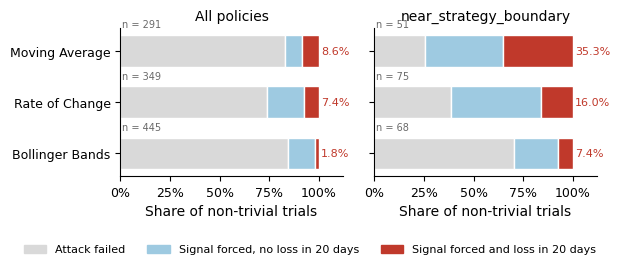

In [26]:
STRATEGY_ORDER = ["MA", "ROC", "BB"]
STRATEGY_NAMES = {"MA": "Moving Average", "ROC": "Rate of Change", "BB": "Bollinger Bands"}
STRATEGY_COLORS = {"MA": "#c0392b", "ROC": "#2e5fa3", "BB": "#1e8449"}

mpl.rcParams.update({
    "font.size": 10, "axes.labelsize": 10, "legend.fontsize": 9,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "pdf.fonttype": 42,
})

frames = []
for s in STRATEGY_ORDER:
    path = RUN_DIR / f"ALL_LSTM_{s}{SUFFIX}" / f"ALL_LSTM_{s}.csv"
    df = pd.read_csv(path)
    df["strategy"] = s
    frames.append(df)
trials = pd.concat(frames, ignore_index=True)

trials = trials[trials["valid"].astype(bool)].copy()
trials["success"] = trials["success"].astype(bool)
trials["already_target"] = trials["already_target"].astype(bool)
trials["nontrivial"] = ~trials["already_target"]
trials["nt_success"] = trials["success"] & trials["nontrivial"]
trials["harmful"] = trials["nt_success"] & (trials["delta_cumulative_return_in_period"] < 0)

def outcome_shares(df):
    nt = df[df["nontrivial"]]
    n = len(nt)
    failed = (~nt["nt_success"]).sum()
    harmful = nt["harmful"].sum()
    forced_no_loss = nt["nt_success"].sum() - harmful
    return n, np.array([failed, forced_no_loss, harmful]) / n

groups = [
    ("All policies", trials),
    ("near_strategy_boundary", trials[trials["timing_policy"] == "near_strategy_boundary"]),
]
parts = ["Attack failed", "Signal forced, no loss in 20 days", "Signal forced and loss in 20 days"]
part_colors = ["#d9d9d9", "#9ecae1", "#c0392b"]

fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.6), sharey=True)
for ax, (title, df) in zip(axes, groups):
    labels = []
    for i, s in enumerate(STRATEGY_ORDER):
        n, shares = outcome_shares(df[df["strategy"] == s])
        left = 0.0
        for share, color in zip(shares, part_colors):
            ax.barh(i, share * 100, left=left, color=color, edgecolor="white", height=0.62)
            left += share * 100
        # label of the last segment (harmful share)
        ax.text(101, i, f"{shares[2] * 100:.1f}%", va="center", ha="left", fontsize=8, color="#c0392b")
        ax.text(1, i - 0.42, f"n = {n}", va="bottom", ha="left", fontsize=7, color="dimgray")
        labels.append(STRATEGY_NAMES[s])
    ax.set_yticks(range(len(STRATEGY_ORDER)))
    ax.set_yticklabels(labels)
    ax.set_xlim(0, 112)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"])
    ax.set_xlabel("Share of non-trivial trials")
    ax.set_title(title, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].invert_yaxis()   # once: the y axis is shared
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in part_colors]
fig.legend(handles, parts, loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, -0.04), fontsize=8)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()